# Research questions 2 and 3: outcomes

**Question 2.** Do the shares of successful and unsuccessful requests differ by agency group?

**H₀.** The success rate is the same across agency groups.
**H₁.** The success rate differs across agency groups.

Question 2 uses `data/processed/frame_2025.csv`, which has every public request filed in 2025 and already carries a status. The success rate is the number of `successful` or `partially successful` requests divided by all requests in the group, including those still open or referred, because open and referred requests keep their own categories instead of being recoded as unsuccessful, and the chart shows every outcome. These shares reflect each request's status on 29 September 2026, so requests filed late in 2025 have had less time to close.

**Question 3.** Among closed requests, are faster first responses linked to a successful outcome?

**H₀.** First-response time is not related to the outcome of a closed request.
**H₁.** Closed requests with a faster first response are more likely to end successfully.

Question 3 uses the sample, because only the detail pages have reply timestamps, and "closed" means `is_final`: successful, partially successful, denied, or closed. Requests with no agency reply have no response time, so they stay out of the main comparison, and a separate check near the end adds them back. The overall medians and the Mann–Whitney test use `sampling_weight`, while the within-group tests simply compare the rows as drawn, since the weights barely vary inside a single group. As before, the first agency message may be only an acknowledgment.

About the weights: the stored `sampling_weight` divides each stratum's population by the number of requests drawn, but 22 drawn pages were no longer public (20 law enforcement and 2 national agency requests, all filed in Q1), so those strata hold fewer rows than we drew. We therefore recompute the weight here with `collected_weights` (in `scripts/analysis.py`), which divides by the number actually collected and makes the weights add up to the 14,668 requests in the frame.

As in the other notebooks, this one only prints aggregates and never shows titles, purposes, tracking numbers, or source URLs.

In [1]:
from pathlib import Path
import sys

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from scipy.stats import chi2_contingency, mannwhitneyu

ROOT = Path("..")
sys.path.insert(0, str(ROOT / "scripts"))
from analysis import (
    collected_weights,
    GROUP_ORDER,
    LABELS,
    OUTCOME_ORDER,
    SUCCESSFUL_OUTCOMES,
    weighted_mannwhitney,
    weighted_mean,
    weighted_median,
    weighted_quartile_edges,
)

ALPHA = 0.05

frame = pd.read_csv(ROOT / "data/processed/frame_2025.csv")
sample = pd.read_csv(ROOT / "data/processed/efoi_2025.csv", parse_dates=["filed_at"])
sample["first_response_days"] = pd.to_numeric(sample["first_response_days"], errors="coerce")
sample["sampling_weight"] = collected_weights(sample)
sample["is_final"] = sample["is_final"].astype("boolean")
sample["is_successful"] = sample["is_successful"].astype("boolean")
frame["is_successful"] = frame["outcome"].isin(SUCCESSFUL_OUTCOMES)

print(f"Frame: {len(frame):,} public requests filed in 2025")
print(f"Sample: {len(sample):,} requests with reply timelines")

Frame: 14,668 public requests filed in 2025
Sample: 1,641 requests with reply timelines


## Question 2: success shares

The success rate is the share of all requests in a group that ended successful or partially successful, with open and referred requests staying in the denominator.

In [2]:
counts = pd.crosstab(frame["agency_group"], frame["outcome"]).reindex(GROUP_ORDER)[OUTCOME_ORDER]
shares = counts.div(counts.sum(axis=1), axis=0)
summary = pd.DataFrame({
    "n": counts.sum(axis=1),
    "successful_pct": shares["successful"] * 100,
    "partial_pct": shares["partially successful"] * 100,
    "unsuccessful_pct": shares["unsuccessful"] * 100,
    "open_pct": shares["open"] * 100,
    "referred_pct": shares["referred"] * 100,
})
summary["success_rate"] = shares["successful"] + shares["partially successful"]
shown = summary.copy()
shown["success_pct"] = (shown["success_rate"] * 100).round(1)
shown = shown.drop(columns="success_rate")
percent_columns = ["successful_pct", "partial_pct", "unsuccessful_pct", "open_pct", "referred_pct"]
shown[percent_columns] = shown[percent_columns].round(1)
display(shown)
print(f"Requests in the frame: {len(frame):,}")

,n,successful_pct,partial_pct,unsuccessful_pct,open_pct,referred_pct,success_pct
agency_group,,,,,,,
NGA,12219,47.4,15.7,25.8,6.0,5.1,63.0
GOCC,1284,55.1,9.5,22.8,10.4,2.3,64.6
SUC,344,52.3,0.6,26.2,17.2,3.8,52.9
WATER-DISTRICT,287,32.1,1.0,43.6,22.6,0.7,33.1
LGU,175,70.3,4.6,7.4,16.6,1.1,74.9
LEA,359,61.3,2.2,35.4,1.1,0.0,63.5


Requests in the frame: 14,668


## Outcome shares

Groups are ordered by success rate, and each bar shows the mix of outcomes among all requests in the group, so its five segments add up to 100%. The rate in each label counts partially successful requests as successes.

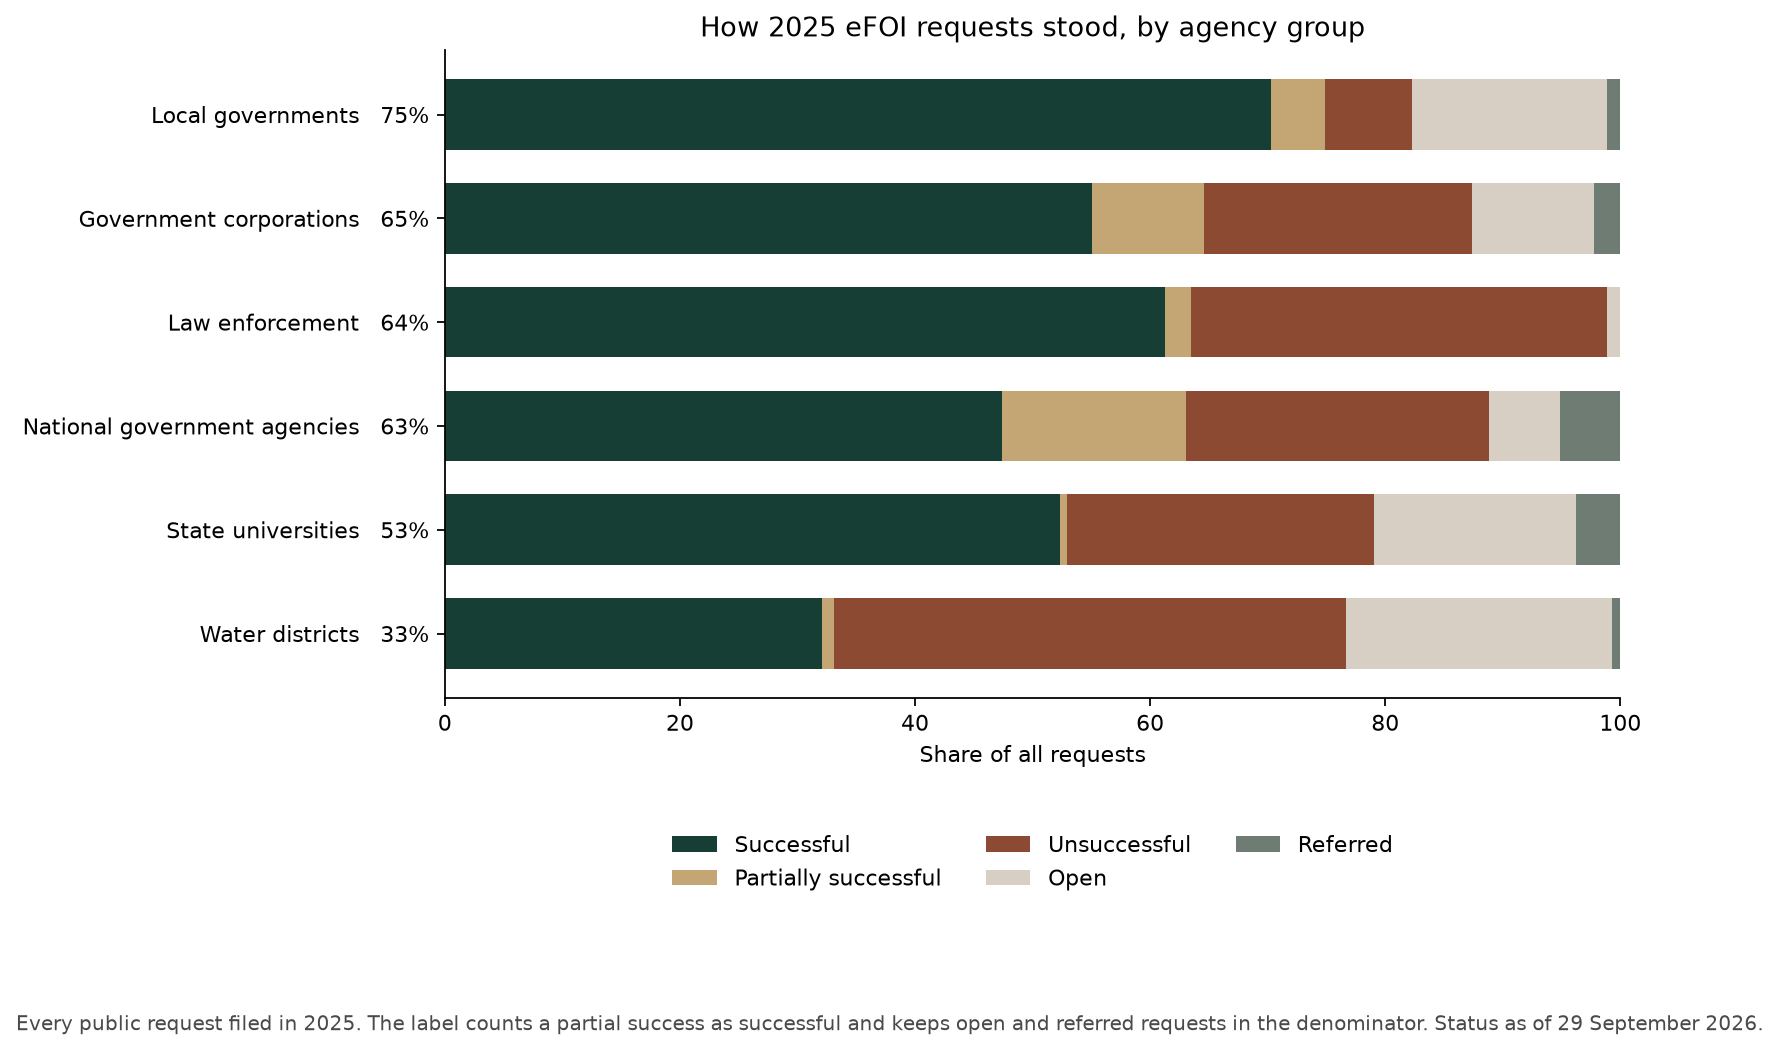

Saved ../reports/figures/rq2_outcome_shares.png


In [3]:
plot_order = summary.sort_values("success_rate", ascending=True).index.tolist()
plot_labels = [
    f"{LABELS[group]}   {summary.loc[group, 'success_rate']:.0%}"
    for group in plot_order
]
ink = "#173e35"
sand = "#c4a574"
accent = "#8c4a32"
open_color = "#d7cfc3"
referred_color = "#6e7c74"
segment_colors = {
    "successful": ink,
    "partially successful": sand,
    "unsuccessful": accent,
    "open": open_color,
    "referred": referred_color,
}
segment_labels = {
    "successful": "Successful",
    "partially successful": "Partially successful",
    "unsuccessful": "Unsuccessful",
    "open": "Open",
    "referred": "Referred",
}

fig, ax = plt.subplots(figsize=(10.2, 5.6), constrained_layout=True)
left = np.zeros(len(plot_order))
for outcome in OUTCOME_ORDER:
    segment = shares.loc[plot_order, outcome].to_numpy() * 100
    ax.barh(
        plot_labels,
        segment,
        left=left,
        color=segment_colors[outcome],
        height=0.68,
        label=segment_labels[outcome],
    )
    left = left + segment
ax.set_xlim(0, 100)
ax.set_xlabel("Share of all requests")
ax.set_title("How 2025 eFOI requests stood, by agency group")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper center", ncol=3, bbox_to_anchor=(0.5, -0.18))
fig.text(
    0,
    -0.14,
    "Every public request filed in 2025. The label counts a partial success as successful and keeps open and referred requests in the denominator. Status as of 29 September 2026.",
    fontsize=9,
    color="#4a4a4a",
)

fig_dir = ROOT / "reports" / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)
share_path = fig_dir / "rq2_outcome_shares.png"
fig.savefig(share_path, dpi=160, bbox_inches="tight")
plt.close(fig)
display(Image(filename=str(share_path)))
print(f"Saved {share_path.as_posix()}")

## Chi-square test

The test compares successes against all other outcomes across the six groups, using every request in the frame and counting partially successful requests as successes. One thing to keep in mind when reading the p-value is that the frame isn't a sample but every public request filed in 2025, so with 14,668 requests even a small difference between groups produces a tiny p-value. Cramér's V, which measures how big the difference is on a 0–1 scale, is therefore the more useful number here, and values near 0.1 are usually read as a weak association.

In [4]:
outcome_table = pd.crosstab(frame["agency_group"], frame["is_successful"]).reindex(GROUP_ORDER)
outcome_table.columns = ["not successful", "successful"]
chi2, chi_p, dof, expected = chi2_contingency(outcome_table)
n_frame = int(outcome_table.to_numpy().sum())
cramer_v = (chi2 / (n_frame * (min(outcome_table.shape) - 1))) ** 0.5

display(outcome_table)
print(f"Chi-square = {chi2:.2f}, df = {dof}, p = {chi_p:.4g}")
print(f"Cramer's V = {cramer_v:.3f}")
print(f"Smallest expected count: {expected.min():.1f}")

,not successful,successful
agency_group,,
NGA,4516,7703
GOCC,455,829
SUC,162,182
WATER-DISTRICT,192,95
LGU,44,131
LEA,131,228


Chi-square = 134.77, df = 5, p = 2.316e-27
Cramer's V = 0.096
Smallest expected count: 65.6


## Does the definition of success change the answer?

The success rate above keeps open and referred requests in the denominator, which pulls down the rate for groups with many requests still open: between 17% and 23% of local government, state university and water district requests were still open on the collection date. Another reasonable approach counts closed requests only, dividing successes by successes plus failures, and the table below compares the two. If the chi-square result held under only one definition, the answer to Question 2 would depend on that choice.

In [5]:
closed_frame = frame.loc[frame["outcome"].isin(["successful", "partially successful", "unsuccessful"])]
closed_table = pd.crosstab(closed_frame["agency_group"], closed_frame["is_successful"]).reindex(GROUP_ORDER)
closed_table.columns = ["unsuccessful", "successful"]
closed_rate = closed_table["successful"] / closed_table.sum(axis=1)

compare = pd.DataFrame({
    "all_requests_pct": (summary["success_rate"] * 100).round(1),
    "rank_all": summary["success_rate"].rank(ascending=False).astype(int),
    "closed_only_pct": (closed_rate * 100).round(1),
    "rank_closed": closed_rate.rank(ascending=False).astype(int),
})
display(compare)

chi2_closed, p_closed, dof_closed, expected_closed = chi2_contingency(closed_table)
n_closed = int(closed_table.to_numpy().sum())
v_closed = (chi2_closed / (n_closed * (min(closed_table.shape) - 1))) ** 0.5
print(f"Closed requests only: chi-square = {chi2_closed:.2f}, df = {dof_closed}, p = {p_closed:.4g}, Cramer's V = {v_closed:.3f}")
print(f"Smallest expected count: {expected_closed.min():.1f}")

,all_requests_pct,rank_all,closed_only_pct,rank_closed
agency_group,,,,
NGA,63.0,4,71.0,3
GOCC,64.6,2,73.9,2
SUC,52.9,5,66.9,4
WATER-DISTRICT,33.1,6,43.2,6
LGU,74.9,1,91.0,1
LEA,63.5,3,64.2,5


Closed requests only: chi-square = 123.88, df = 5, p = 4.73e-25, Cramer's V = 0.098
Smallest expected count: 42.2


Every rate goes up once open requests leave the denominator, with local governments and state universities gaining the most, about 15 percentage points each. The order shifts in the middle, because law enforcement has almost no open requests and so drops behind groups whose rates were held down by open cases. The test result doesn't change, though: under both definitions the groups differ, and the association is weak (V close to 0.1).

## Question 3: speed and success

The comparison uses closed requests that have a first-response time, and the chart splits them into four groups of equal population weight, from the fastest quarter to the slowest. The overall test is a weighted Mann–Whitney comparison that asks whether a successful request tended to wait longer or shorter than an unsuccessful one, counting each request in proportion to its sampling weight. Because response times aren't normal (notebook 01), the test uses ranks rather than means, and the within-group tests are unweighted since the weights barely vary inside a group. H₁ predicts a direction, that faster replies go with success, but we still report the two-sided p-value, which is the stricter choice and lets a difference in either direction show up.

In [6]:
closed = sample.loc[sample["is_final"]].copy()
missing_time = closed["first_response_days"].isna()
timed = closed.loc[~missing_time].copy()

print(f"Closed requests: {len(closed):,}")
print(f"Closed requests with no first response: {int(missing_time.sum()):,}")
print("Outcomes among those with no first response:")
display(closed.loc[missing_time, "outcome"].value_counts().rename("requests").to_frame())

edges = weighted_quartile_edges(timed["first_response_days"], timed["sampling_weight"])
low = float(timed["first_response_days"].min())
high = float(timed["first_response_days"].max())
bounds = [low, *edges, high]
band_labels = [f"{bounds[i]:.1f}–{bounds[i + 1]:.1f} days" for i in range(len(bounds) - 1)]
timed["speed_band"] = pd.cut(
    timed["first_response_days"],
    bins=[-np.inf, *edges, np.inf],
    labels=band_labels,
)
band_rows = []
for band, part in timed.groupby("speed_band", observed=True):
    band_rows.append({
        "band": str(band),
        "success_rate": weighted_mean(part["is_successful"].astype(float), part["sampling_weight"]),
        "n": len(part),
    })
band_rates = pd.DataFrame(band_rows).set_index("band")
display((band_rates.assign(success_pct=(band_rates["success_rate"] * 100).round(1))).drop(columns="success_rate"))

success_rows = timed.loc[timed["is_successful"]]
fail_rows = timed.loc[~timed["is_successful"]]
success_median = weighted_median(success_rows["first_response_days"], success_rows["sampling_weight"])
fail_median = weighted_median(fail_rows["first_response_days"], fail_rows["sampling_weight"])
print(f"Weighted median days, successful: {success_median:.2f} (n = {len(success_rows):,})")
print(f"Weighted median days, unsuccessful: {fail_median:.2f} (n = {len(fail_rows):,})")

Closed requests: 1,409
Closed requests with no first response: 22
Outcomes among those with no first response:


,requests
outcome,
unsuccessful,22


,n,success_pct
band,,
0.0–0.6 days,362,71.9
0.6–1.3 days,314,67.7
1.3–3.9 days,275,78.3
3.9–527.0 days,436,67.1


Weighted median days, successful: 1.51 (n = 968)
Weighted median days, unsuccessful: 1.01 (n = 419)


## Success rate by speed

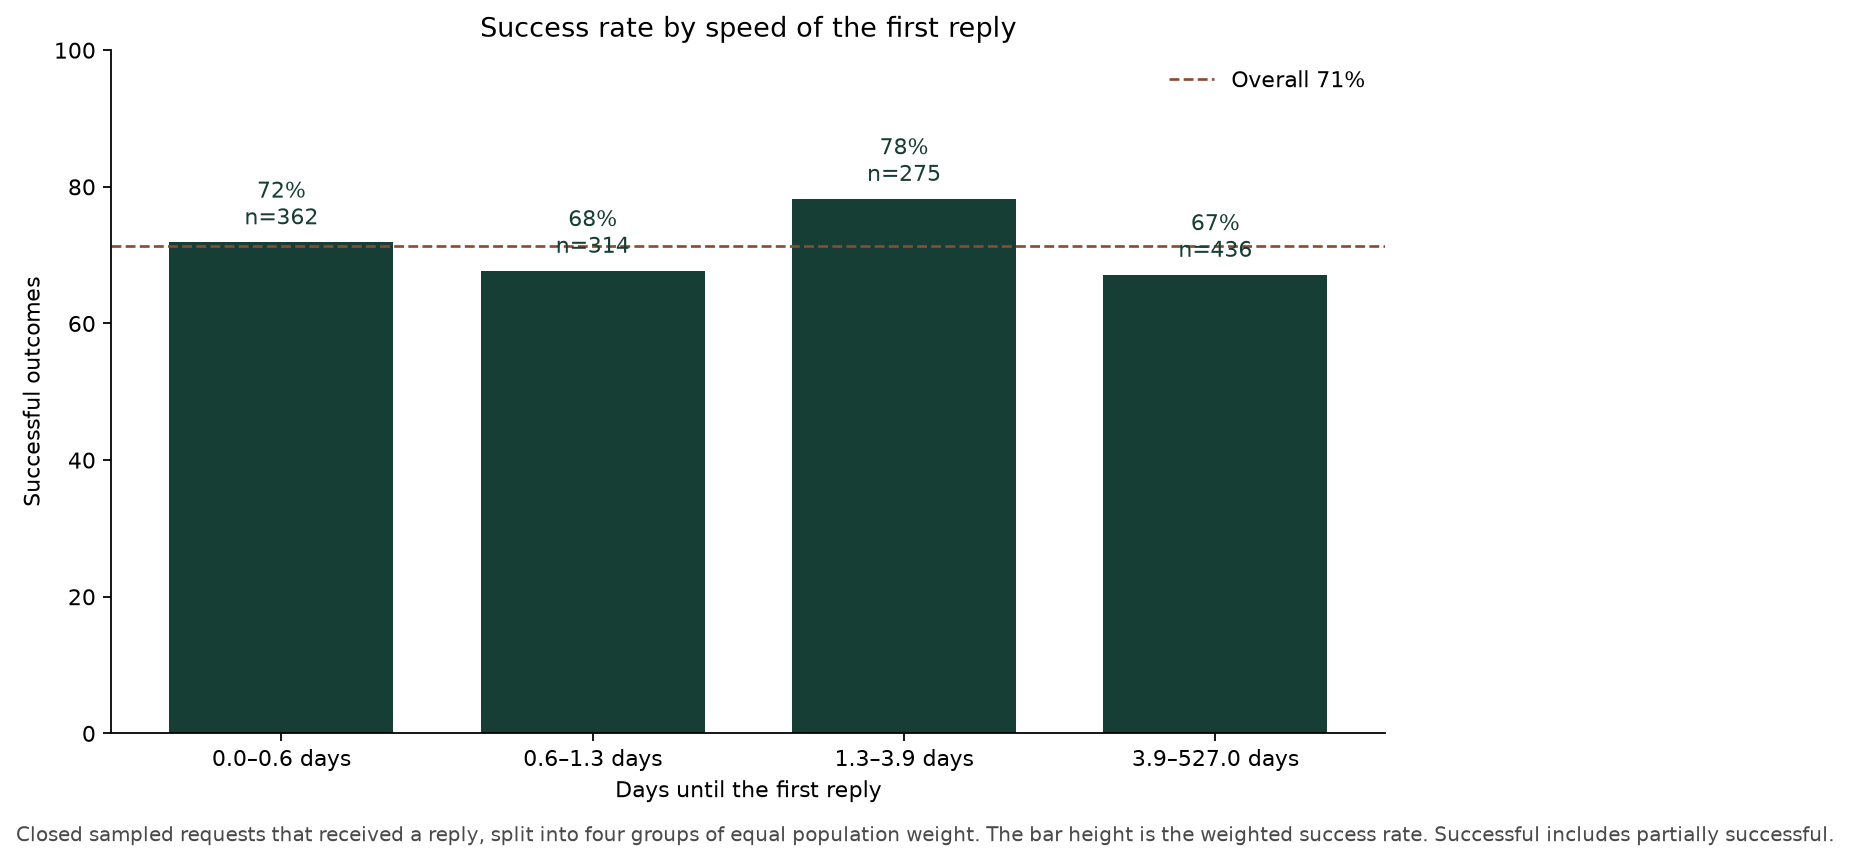

Saved ../reports/figures/rq3_speed_and_success.png


In [7]:
fig, ax = plt.subplots(figsize=(8.6, 5.0), constrained_layout=True)
percents = band_rates["success_rate"] * 100
bars = ax.bar(band_rates.index, percents, color=ink, width=0.72)
overall_pct = weighted_mean(timed["is_successful"].astype(float), timed["sampling_weight"]) * 100
ax.axhline(overall_pct, color=accent, linestyle="--", linewidth=1.2, label=f"Overall {overall_pct:.0f}%")
for bar, pct, n in zip(bars, percents, band_rates["n"]):
    ax.text(bar.get_x() + bar.get_width() / 2, pct + 1.5, f"{pct:.0f}%\nn={int(n)}", ha="center", va="bottom", fontsize=10, color=ink)
ax.set_ylim(0, 100)
ax.set_ylabel("Successful outcomes")
ax.set_xlabel("Days until the first reply")
ax.set_title("Success rate by speed of the first reply")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper right")
fig.text(
    0,
    -0.04,
    "Closed sampled requests that received a reply, split into four groups of equal population weight. The bar height is the weighted success rate. Successful includes partially successful.",
    fontsize=9,
    color="#4a4a4a",
)
speed_path = fig_dir / "rq3_speed_and_success.png"
fig.savefig(speed_path, dpi=160, bbox_inches="tight")
plt.close(fig)
display(Image(filename=str(speed_path)))
print(f"Saved {speed_path.as_posix()}")

## Mann–Whitney test

The overall test pools every agency group and weights each request by `sampling_weight`, since without weights the smaller groups, which we sampled much more heavily, would stand in for national agencies. The table below then repeats the comparison inside each group.

In [8]:
probability, weighted_p = weighted_mannwhitney(
    timed["first_response_days"],
    timed["sampling_weight"],
    timed["is_successful"].to_numpy(dtype=bool),
)
print(f"Weighted probability that a success waited longer: {probability:.3f}")
print(f"p = {weighted_p:.3f}")

within_rows = []
for group in GROUP_ORDER:
    part = timed.loc[timed["agency_group"] == group]
    succeeded = part.loc[part["is_successful"]]
    failed = part.loc[~part["is_successful"]]
    group_test = mannwhitneyu(
        succeeded["first_response_days"],
        failed["first_response_days"],
        alternative="two-sided",
    )
    within_rows.append({
        "agency_group": group,
        "n_successful": len(succeeded),
        "n_unsuccessful": len(failed),
        "median_successful": weighted_median(succeeded["first_response_days"], succeeded["sampling_weight"]),
        "median_unsuccessful": weighted_median(failed["first_response_days"], failed["sampling_weight"]),
        "p": group_test.pvalue,
    })
within = pd.DataFrame(within_rows).set_index("agency_group")
shown_within = within.copy()
shown_within["median_successful"] = shown_within["median_successful"].round(2)
shown_within["median_unsuccessful"] = shown_within["median_unsuccessful"].round(2)
shown_within["p"] = shown_within["p"].map(lambda value: f"{value:.3g}")
display(shown_within)

Weighted probability that a success waited longer: 0.500
p = 0.989


,n_successful,n_unsuccessful,median_successful,median_unsuccessful,p
agency_group,,,,,
NGA,196,80,1.42,0.93,0.949
GOCC,195,55,2.65,3.04,0.911
SUC,165,74,2.99,3.72,0.366
WATER-DISTRICT,95,105,1.07,1.13,0.674
LGU,131,13,4.38,7.74,0.401
LEA,186,92,0.53,0.65,0.108


## The closed requests with no reply

The test above leaves out closed requests where the agency never posted a message, because they have no response time. All of them ended unsuccessful and most are water district requests, so leaving them out could hide a link: no reply at all is the slowest possible response, and it always failed. To check, we add them back and rank them as slower than every request that got a reply, and the exact number we assign doesn't matter because the test only uses ranks.

In [9]:
slowest = closed["first_response_days"].max() + 1
with_no_reply = closed["first_response_days"].fillna(slowest)
probability_all, weighted_p_all = weighted_mannwhitney(
    with_no_reply,
    closed["sampling_weight"],
    closed["is_successful"].to_numpy(dtype=bool),
)
print(f"Closed requests with no reply: {int(missing_time.sum())}")
display(closed.loc[missing_time, "agency_group"].value_counts().rename("requests").to_frame())
print(f"All closed requests, no reply ranked slowest: weighted p = {weighted_p_all:.3f} (n = {len(closed):,})")

sensitivity_rows = []
for group in GROUP_ORDER:
    part = closed.loc[closed["agency_group"] == group]
    if not part["first_response_days"].isna().any():
        continue
    days = part["first_response_days"].fillna(slowest)
    is_success = part["is_successful"].to_numpy(dtype=bool)
    sensitivity_rows.append({
        "agency_group": group,
        "no_reply": int(part["first_response_days"].isna().sum()),
        "p_without": within.loc[group, "p"],
        "p_with": mannwhitneyu(days[is_success], days[~is_success], alternative="two-sided").pvalue,
    })
sensitivity = pd.DataFrame(sensitivity_rows).set_index("agency_group")
display(sensitivity.map(lambda value: f"{value:.3g}" if isinstance(value, float) else value))

Closed requests with no reply: 22


,requests
agency_group,
WATER-DISTRICT,20
GOCC,2


All closed requests, no reply ranked slowest: weighted p = 0.914 (n = 1,409)


,no_reply,p_without,p_with
agency_group,,,
GOCC,2,0.911,0.608
WATER-DISTRICT,20,0.674,0.0164


Across the population the answer doesn't change, because the no-reply requests are a very small share once weighted, so the pooled p-value stays far above 0.05. Water districts are different. Among water district requests that got a reply, speed isn't linked to success, but once we count the requests that never got a reply, the link becomes significant because all of those failed. For water districts, then, whether the agency replies at all matters more than how fast it does. This is a within-group result for one small group, so it doesn't overturn the overall answer to Question 3, but it belongs in the discussion.

## What this says about the questions

In [10]:
lowest = summary["success_rate"].idxmin()
highest = summary["success_rate"].idxmax()
print(
    f"Question 2. The success rate runs from {summary.loc[lowest, 'success_rate']:.1%} "
    f"for {LABELS[lowest]} to {summary.loc[highest, 'success_rate']:.1%} for {LABELS[highest]}."
)
if chi_p < ALPHA:
    print(
        f"Reject H0 at alpha {ALPHA}: chi-square = {chi2:.2f}, df = {dof}, "
        f"p = {chi_p:.4g}, Cramer's V = {cramer_v:.3f}."
    )
    print(
        f"Counting closed requests only gives the same result (p = {p_closed:.4g}, V = {v_closed:.3f}). "
        "The groups differ, but the association is weak."
    )
    print(
        "Status was observed on 29 September 2026, so requests filed late in 2025 have had less time to close."
    )
else:
    print(f"Do not reject H0 at alpha {ALPHA}: chi-square = {chi2:.2f}, p = {chi_p:.4g}.")

print()
print(
    f"Question 3. Among closed requests with a reply, the weighted median first response is "
    f"{success_median:.1f} days for a successful outcome and {fail_median:.1f} days for an unsuccessful one."
)
spread = band_rates["success_rate"].max() - band_rates["success_rate"].min()
print(f"Weighted success rates across the four speed groups differ by at most {spread * 100:.1f} percentage points, with no steady trend.")
if weighted_p < ALPHA:
    print(f"Reject H0 at alpha {ALPHA}: weighted Mann-Whitney p = {weighted_p:.3f}.")
else:
    print(
        f"Do not reject H0 at alpha {ALPHA}: weighted Mann-Whitney p = {weighted_p:.2f}. "
        "We found no evidence that a faster first reply goes with a successful outcome. "
        "This does not prove there is no link; it means this data does not show one."
    )
if (within["p"] < ALPHA).any():
    print("At least one agency group shows a within-group difference at alpha 0.05.")
else:
    print("Inside every agency group the comparison stays above 0.05.")
print(
    f"Putting back the {int(missing_time.sum())} closed requests with no reply (all unsuccessful) "
    f"leaves the overall result unchanged (weighted p = {weighted_p_all:.2f})."
)
flipped = sensitivity.loc[(sensitivity["p_with"] < ALPHA) & (sensitivity["p_without"] >= ALPHA)]
for group in flipped.index:
    print(
        f"In {LABELS[group].lower()}, the comparison becomes significant (p = {flipped.loc[group, 'p_with']:.3f}): "
        "getting no reply at all goes with failure there."
    )

Question 2. The success rate runs from 33.1% for Water districts to 74.9% for Local governments.
Reject H0 at alpha 0.05: chi-square = 134.77, df = 5, p = 2.316e-27, Cramer's V = 0.096.
Counting closed requests only gives the same result (p = 4.73e-25, V = 0.098). The groups differ, but the association is weak.
Status was observed on 29 September 2026, so requests filed late in 2025 have had less time to close.

Question 3. Among closed requests with a reply, the weighted median first response is 1.5 days for a successful outcome and 1.0 days for an unsuccessful one.
Weighted success rates across the four speed groups differ by at most 11.1 percentage points, with no steady trend.
Do not reject H0 at alpha 0.05: weighted Mann-Whitney p = 0.99. We found no evidence that a faster first reply goes with a successful outcome. This does not prove there is no link; it means this data does not show one.
Inside every agency group the comparison stays above 0.05.
Putting back the 22 closed reque